# 03 — Frozen ResNet-18 Embeddings + Logistic Regression Baseline

This notebook builds the required low-cost baseline for the MURA XR_WRIST project.

Pipeline: each X-ray image → frozen ImageNet ResNet-18 → 512-dimensional embedding → mean embedding per study → Logistic Regression → study-level NORMAL / ABNORMAL probability.

It uses only the cleaned internal train and validation manifests from Notebook 02. It does not read the official MURA validation split and does not create a new split.


In [1]:
import io
import json
import random
import time
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


Device: cpu
Torch: 2.11.0+cpu
Torchvision: 0.26.0+cpu


In [2]:
from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
# Change only this path if your Google Drive layout is different.

DATA_DIR = Path("/content/drive/MyDrive/DATA")
RAW_ZIP = DATA_DIR / "MURA-v1.1_files.zip"
PREPROCESSING_DIR = DATA_DIR / "PREPROCESSED_WRIST"
OUTPUT_DIR = DATA_DIR / "BASELINE_MODEL_A"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_MANIFEST = PREPROCESSING_DIR / "wrist_internal_train_clean.csv"
VALIDATION_MANIFEST = PREPROCESSING_DIR / "wrist_internal_val_clean.csv"
PREPROCESSING_SPEC = PREPROCESSING_DIR / "preprocessing_spec.json"

for required_path in (RAW_ZIP, TRAIN_MANIFEST, VALIDATION_MANIFEST):
    assert required_path.exists(), "Not found: {}".format(required_path)

print("Raw ZIP:       ", RAW_ZIP)
print("Train manifest:", TRAIN_MANIFEST)
print("Val manifest:  ", VALIDATION_MANIFEST)
print("Output folder: ", OUTPUT_DIR)


Raw ZIP:        /content/drive/MyDrive/DATA/MURA-v1.1_files.zip
Train manifest: /content/drive/MyDrive/DATA/PREPROCESSED_WRIST/wrist_internal_train_clean.csv
Val manifest:   /content/drive/MyDrive/DATA/PREPROCESSED_WRIST/wrist_internal_val_clean.csv
Output folder:  /content/drive/MyDrive/DATA/BASELINE_MODEL_A


In [ ]:
# OVERWRITE PROTECTION (added 17.10.2026, after the run recorded in this notebook).
# BASELINE_MODEL_A holds the frozen Model A: Notebooks 04-07 read it and 06a stores the sha256 of its files.
# If any output of this notebook already exists there, this run writes to a NEW folder
# DATA/RUNS_ARTEM/03_BASELINE_MODEL_A/run_<UTC time>/ and leaves the existing files unchanged.
# Run this cell after the paths cell above and before any cell that saves files.
from datetime import datetime, timezone

CANONICAL_OUTPUT_DIR = DATA_DIR / "BASELINE_MODEL_A"
OUTPUT_FILES = [
    "train_study_metadata.csv",
    "train_study_embeddings.npz",
    "validation_study_metadata.csv",
    "validation_study_embeddings.npz",
    "frozen_resnet18_mean_embedding_logreg.joblib",
    "validation_predictions.csv",
    "validation_ranking_metrics.json",
    "model_selection.json",
    "logistic_regression_candidates.csv",
    "run_metadata.json",
]
already_saved = [name for name in OUTPUT_FILES if (CANONICAL_OUTPUT_DIR / name).exists()]
if already_saved:
    run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
    OUTPUT_DIR = DATA_DIR / "RUNS_ARTEM" / "03_BASELINE_MODEL_A" / run_id
    OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
    print(f"{len(already_saved)} of {len(OUTPUT_FILES)} outputs already exist in {CANONICAL_OUTPUT_DIR}; left unchanged.")
else:
    OUTPUT_DIR = CANONICAL_OUTPUT_DIR
assert not any((OUTPUT_DIR / name).exists() for name in OUTPUT_FILES), "Refusing to overwrite existing outputs"
print("This run writes to:", OUTPUT_DIR)

## Load the cleaned manifests

Notebook 02 already checked image readability and created the clean manifests. This notebook does not repeat the cleaning step.


In [4]:
train_views = pd.read_csv(TRAIN_MANIFEST)
validation_views = pd.read_csv(VALIDATION_MANIFEST)

REQUIRED_COLUMNS = {"patient_id", "study_uid", "label_binary"}
for split_name, frame in {
    "train": train_views,
    "validation": validation_views,
}.items():
    missing = REQUIRED_COLUMNS - set(frame.columns)
    assert not missing, "{} is missing {}".format(split_name, sorted(missing))
    assert frame["label_binary"].isin([0, 1]).all()
    assert frame.groupby("study_uid")["label_binary"].nunique().max() == 1

PATH_CANDIDATES = ("image_path", "relative_path", "path", "file_name")
PATH_COLUMN = next(
    (column for column in PATH_CANDIDATES if column in train_views.columns),
    None,
)
assert PATH_COLUMN is not None, "No image path column found."
assert PATH_COLUMN in validation_views.columns

assert set(train_views["patient_id"].astype(str)).isdisjoint(
    set(validation_views["patient_id"].astype(str))
), "Patient leakage detected."

assert set(train_views["study_uid"].astype(str)).isdisjoint(
    set(validation_views["study_uid"].astype(str))
), "Study leakage detected."

for frame in (train_views, validation_views):
    invalid_metadata = frame[PATH_COLUMN].astype(str).str.split("/").str[-1].str.startswith("._")
    assert not invalid_metadata.any(), "The clean manifest still contains AppleDouble files."

print("Input contract passed.")
print("Image path column:", PATH_COLUMN)


Input contract passed.
Image path column: file_name


In [5]:
def summarize_split(frame, split_name):
    studies = frame.drop_duplicates("study_uid")
    return {
        "split": split_name,
        "images": len(frame),
        "studies": studies["study_uid"].nunique(),
        "patients": studies["patient_id"].nunique(),
        "normal_studies": int((studies["label_binary"] == 0).sum()),
        "abnormal_studies": int((studies["label_binary"] == 1).sum()),
    }

split_summary = pd.DataFrame([
    summarize_split(train_views, "train"),
    summarize_split(validation_views, "validation"),
])
display(split_summary)


,split,images,studies,patients,normal_studies,abnormal_studies
0,train,7810,2769,2614,1712,1057
1,validation,1942,691,653,422,269


## Deterministic image transform

The transform is the same as Notebook 02. For the frozen embedding baseline, no augmentation is used.


In [6]:
class PadToSquare:
    def __call__(self, image):
        width, height = image.size
        side = max(width, height)

        left = (side - width) // 2
        top = (side - height) // 2
        right = side - width - left
        bottom = side - height - top

        return ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill=0,
        )

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

evaluation_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("L")),
    PadToSquare(),
    transforms.Resize(
        (224, 224),
        interpolation=InterpolationMode.BILINEAR,
        antialias=True,
    ),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

if PREPROCESSING_SPEC.exists():
    preprocessing_spec = json.loads(PREPROCESSING_SPEC.read_text(encoding="utf-8"))
    assert preprocessing_spec["input_resolution"] == [224, 224]
    print("Notebook 02 preprocessing specification checked.")

print("Evaluation transform ready.")


Notebook 02 preprocessing specification checked.
Evaluation transform ready.


## Dataset and DataLoaders

Images are read from the original ZIP file. The notebook does not copy raw images into a new folder.


In [7]:
def resolve_zip_member(value, members):
    normalized = str(value).replace("\\", "/").lstrip("/")

    for candidate in (normalized, "MURA-v1.1/" + normalized):
        if candidate in members:
            return candidate

    raise KeyError("Image path not found in ZIP: {}".format(value))


class MURAWristZipDataset(Dataset):
    def __init__(self, dataframe, zip_path, transform, path_column):
        self.frame = dataframe.reset_index(drop=True).copy()
        self.zip_path = str(zip_path)
        self.transform = transform
        self.path_column = path_column
        self._archive = None
        self._members = None

    def __len__(self):
        return len(self.frame)

    def _open_archive(self):
        if self._archive is None:
            self._archive = zipfile.ZipFile(self.zip_path, "r")
            self._members = set(self._archive.namelist())

    def __getitem__(self, index):
        self._open_archive()
        row = self.frame.iloc[index]
        member = resolve_zip_member(row[self.path_column], self._members)

        with self._archive.open(member) as handle:
            image = Image.open(io.BytesIO(handle.read())).copy()

        return self.transform(image), int(row["label_binary"]), index

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_archive"] = None
        state["_members"] = None
        return state


In [8]:
BATCH_SIZE = 32
NUM_WORKERS = 0

train_dataset = MURAWristZipDataset(
    train_views,
    RAW_ZIP,
    evaluation_transform,
    PATH_COLUMN,
)
validation_dataset = MURAWristZipDataset(
    validation_views,
    RAW_ZIP,
    evaluation_transform,
    PATH_COLUMN,
)

loader_settings = {
    "batch_size": BATCH_SIZE,
    "shuffle": False,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}

train_loader = DataLoader(train_dataset, **loader_settings)
validation_loader = DataLoader(validation_dataset, **loader_settings)

images, labels, indices = next(iter(train_loader))
assert tuple(images.shape[1:]) == (3, 224, 224)
assert torch.isfinite(images).all()

print("Train images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Example batch:", tuple(images.shape))


Train images: 7810
Validation images: 1942
Example batch: (32, 3, 224, 224)


## Frozen ResNet-18 image encoder

The last classification layer is removed. The encoder produces a 512-dimensional embedding for each image and is never fine-tuned in this notebook.


In [9]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
encoder = models.resnet18(weights=weights)

for parameter in encoder.parameters():
    parameter.requires_grad = False

encoder.fc = nn.Identity()
encoder = encoder.to(DEVICE)
encoder.eval()

with torch.inference_mode():
    check_embedding = encoder(images[:2].to(DEVICE))

assert tuple(check_embedding.shape) == (2, 512)
print("Embedding shape:", tuple(check_embedding.shape))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 129MB/s]


Embedding shape: (2, 512)


In [10]:
def extract_embeddings(encoder, loader, device, split_name):
    encoder.eval()

    embedding_batches = []
    index_batches = []

    with torch.inference_mode():
        for batch_images, _, batch_indices in tqdm(
            loader,
            desc="Extracting {} embeddings".format(split_name),
        ):
            batch_embeddings = encoder(
                batch_images.to(device, non_blocking=True)
            ).cpu().numpy().astype(np.float32)

            embedding_batches.append(batch_embeddings)
            index_batches.append(batch_indices.numpy())

    embeddings = np.concatenate(embedding_batches, axis=0)
    row_indices = np.concatenate(index_batches, axis=0)

    assert embeddings.shape == (len(loader.dataset), 512)
    assert len(np.unique(row_indices)) == len(loader.dataset)

    return embeddings, row_indices


In [11]:
started_at = time.time()

train_view_embeddings, train_indices = extract_embeddings(
    encoder,
    train_loader,
    DEVICE,
    "train",
)
validation_view_embeddings, validation_indices = extract_embeddings(
    encoder,
    validation_loader,
    DEVICE,
    "validation",
)

train_metadata = train_views.iloc[train_indices].reset_index(drop=True).copy()
validation_metadata = validation_views.iloc[validation_indices].reset_index(drop=True).copy()

assert len(train_metadata) == len(train_view_embeddings)
assert len(validation_metadata) == len(validation_view_embeddings)

print("Train view embeddings:", train_view_embeddings.shape)
print("Validation view embeddings:", validation_view_embeddings.shape)
print("Minutes:", round((time.time() - started_at) / 60, 1))


Extracting train embeddings:   0%|          | 0/245 [00:00<?, ?it/s]

Extracting validation embeddings:   0%|          | 0/61 [00:00<?, ?it/s]

Train view embeddings: (7810, 512)
Validation view embeddings: (1942, 512)
Minutes: 21.0


## Mean pooling at study level

The model first averages 512-dimensional view embeddings within each study. Logistic Regression is then trained on one row per study. It is not trained separately on each image.


In [12]:
def mean_pool_by_study(metadata, view_embeddings, split_name):
    records = []
    pooled_embeddings = []

    for study_uid, group in metadata.groupby("study_uid", sort=True):
        positions = group.index.to_numpy()

        assert group["patient_id"].nunique() == 1
        assert group["label_binary"].nunique() == 1

        pooled_embeddings.append(view_embeddings[positions].mean(axis=0))
        records.append({
            "split": split_name,
            "patient_id": str(group["patient_id"].iloc[0]),
            "study_id": str(study_uid),
            "label": int(group["label_binary"].iloc[0]),
            "num_views": int(len(group)),
        })

    study_metadata = pd.DataFrame(records)
    study_embeddings = np.vstack(pooled_embeddings).astype(np.float32)

    assert study_metadata["study_id"].is_unique
    assert study_embeddings.shape == (len(study_metadata), 512)

    return study_metadata, study_embeddings


train_studies, train_study_embeddings = mean_pool_by_study(
    train_metadata,
    train_view_embeddings,
    "train",
)
validation_studies, validation_study_embeddings = mean_pool_by_study(
    validation_metadata,
    validation_view_embeddings,
    "validation",
)

assert set(train_studies["patient_id"]).isdisjoint(
    set(validation_studies["patient_id"])
)

display(pd.DataFrame([
    {"split": "train", "studies": len(train_studies), "shape": str(train_study_embeddings.shape)},
    {"split": "validation", "studies": len(validation_studies), "shape": str(validation_study_embeddings.shape)},
]))


,split,studies,shape
0,train,2769,"(2769, 512)"
1,validation,691,"(691, 512)"


In [13]:
def save_embedding_artifact(split_name, metadata, embeddings):
    metadata_path = OUTPUT_DIR / "{}_study_metadata.csv".format(split_name)
    embeddings_path = OUTPUT_DIR / "{}_study_embeddings.npz".format(split_name)

    metadata.to_csv(metadata_path, index=False)
    np.savez_compressed(
        embeddings_path,
        embeddings=embeddings,
        labels=metadata["label"].to_numpy(dtype=np.int64),
        patient_ids=metadata["patient_id"].to_numpy(dtype=str),
        study_ids=metadata["study_id"].to_numpy(dtype=str),
        num_views=metadata["num_views"].to_numpy(dtype=np.int64),
    )

    return metadata_path, embeddings_path


print("Saved:", save_embedding_artifact("train", train_studies, train_study_embeddings))
print("Saved:", save_embedding_artifact("validation", validation_studies, validation_study_embeddings))


Saved: (PosixPath('/content/drive/MyDrive/DATA/BASELINE_MODEL_A/train_study_metadata.csv'), PosixPath('/content/drive/MyDrive/DATA/BASELINE_MODEL_A/train_study_embeddings.npz'))
Saved: (PosixPath('/content/drive/MyDrive/DATA/BASELINE_MODEL_A/validation_study_metadata.csv'), PosixPath('/content/drive/MyDrive/DATA/BASELINE_MODEL_A/validation_study_embeddings.npz'))


## Logistic Regression baseline

Three predefined regularization values are compared. The selection metric is validation AUROC, with a lower C value used as a tie-breaker.


In [14]:
CANDIDATE_C = [0.1, 1.0, 10.0]

y_train = train_studies["label"].to_numpy(dtype=np.int64)
y_validation = validation_studies["label"].to_numpy(dtype=np.int64)

candidate_models = {}
candidate_rows = []

for c_value in CANDIDATE_C:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            C=c_value,
            solver="liblinear",
            max_iter=2000,
            class_weight=None,
            random_state=SEED,
        )),
    ])

    model.fit(train_study_embeddings, y_train)
    probabilities = model.predict_proba(validation_study_embeddings)[:, 1]

    candidate_models[c_value] = model
    candidate_rows.append({
        "C": c_value,
        "validation_auroc": roc_auc_score(y_validation, probabilities),
        "validation_auprc": average_precision_score(y_validation, probabilities),
    })

candidate_results = pd.DataFrame(candidate_rows).sort_values(
    ["validation_auroc", "validation_auprc", "C"],
    ascending=[False, False, True],
).reset_index(drop=True)

best_c = float(candidate_results.iloc[0]["C"])
baseline_model = candidate_models[best_c]
validation_probability = baseline_model.predict_proba(
    validation_study_embeddings
)[:, 1]

display(candidate_results)
print("Selected C:", best_c)


,C,validation_auroc,validation_auprc
0,0.1,0.880442,0.851513
1,1.0,0.867968,0.838206
2,10.0,0.862374,0.831643


Selected C: 0.1


## Validation ranking metrics

These are development metrics on the internal validation split. Threshold selection and a fuller error analysis will be completed in Notebook 04.


,split,auroc,auprc
0,internal_validation,0.880442,0.851513


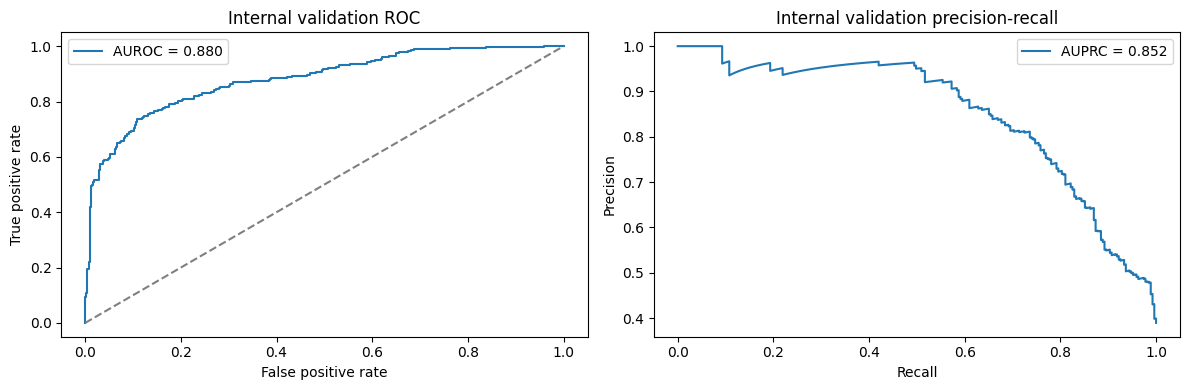

In [15]:
validation_ranking_metrics = {
    "split": "internal_validation",
    "auroc": float(roc_auc_score(y_validation, validation_probability)),
    "auprc": float(average_precision_score(y_validation, validation_probability)),
}

display(pd.DataFrame([validation_ranking_metrics]))

fpr, tpr, _ = roc_curve(y_validation, validation_probability)
precision, recall, _ = precision_recall_curve(y_validation, validation_probability)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    fpr,
    tpr,
    label="AUROC = {:.3f}".format(validation_ranking_metrics["auroc"]),
)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("Internal validation ROC")
axes[0].legend()

axes[1].plot(
    recall,
    precision,
    label="AUPRC = {:.3f}".format(validation_ranking_metrics["auprc"]),
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Internal validation precision-recall")
axes[1].legend()

plt.tight_layout()
plt.show()


## Save outputs for Notebook 04

No official test data is read here. Notebook 04 can select and document the operating threshold using only the validation predictions saved below.


In [16]:
validation_predictions = validation_studies.copy()
validation_predictions["abnormal_probability"] = validation_probability

model_path = OUTPUT_DIR / "frozen_resnet18_mean_embedding_logreg.joblib"
predictions_path = OUTPUT_DIR / "validation_predictions.csv"
metrics_path = OUTPUT_DIR / "validation_ranking_metrics.json"
selection_path = OUTPUT_DIR / "model_selection.json"
candidates_path = OUTPUT_DIR / "logistic_regression_candidates.csv"
run_info_path = OUTPUT_DIR / "run_metadata.json"

joblib.dump(baseline_model, model_path)
validation_predictions.to_csv(predictions_path, index=False)
candidate_results.to_csv(candidates_path, index=False)

metrics_path.write_text(
    json.dumps(validation_ranking_metrics, indent=2),
    encoding="utf-8",
)
selection_path.write_text(
    json.dumps({
        "selection_split": "internal_validation",
        "selection_metric": "AUROC",
        "candidate_c_values": CANDIDATE_C,
        "selected_c": best_c,
        "class_weight": None,
    }, indent=2),
    encoding="utf-8",
)
run_info_path.write_text(
    json.dumps({
        "model": "Frozen ImageNet ResNet-18 embeddings plus Logistic Regression",
        "embedding_dimension": 512,
        "study_pooling": "mean_embedding",
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "device": str(DEVICE),
        "official_mura_valid_read": False,
    }, indent=2),
    encoding="utf-8",
)

print("Saved model:", model_path)
print("Saved validation predictions:", predictions_path)
print("Saved metrics:", metrics_path)


Saved model: /content/drive/MyDrive/DATA/BASELINE_MODEL_A/frozen_resnet18_mean_embedding_logreg.joblib
Saved validation predictions: /content/drive/MyDrive/DATA/BASELINE_MODEL_A/validation_predictions.csv
Saved metrics: /content/drive/MyDrive/DATA/BASELINE_MODEL_A/validation_ranking_metrics.json


## Next step

Run Notebook 04 to choose and document a validation-only operating threshold, calculate threshold metrics, create the confusion matrix, and review false positives and false negatives.
